<a href="https://colab.research.google.com/github/Josphinity/Course-project/blob/main/Statistical_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Mathematical Foundation of ML**


## Numerical Variables

| Variable | What it represents | Why it matters to the project |
|---|---|---|
| Air temperature [K] | Air temperature in Kelvin | Helps examine operating temperature conditions |
| Process temperature [K] | Process temperature in Kelvin | Helps examine temperature during machine operation |
| Rotational speed [rpm] | Rotational speed in revolutions per minute | Helps investigate operating speed patterns |
| Torque [Nm] | Torque in Newton-metres | Helps investigate the relationship between rotational force and machine operation |











In [2]:
from google.colab import files

uploaded = files.upload()

Saving ai4i+2020+predictive+maintenance+dataset (1).zip to ai4i+2020+predictive+maintenance+dataset (1) (1).zip


In [4]:
import pandas as pd
import zipfile

zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall()


df = pd.read_csv("ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
print("Dataset shape:",df.shape)

Dataset shape: (10000, 14)


In [7]:
#select the four numerical variables
variables=['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]']

#calculate descriptive statistics
for variable in variables:
    print("\nVariable:",variable)
    print("Mean:",df[variable].mean())
    print("Median:",df[variable].median())
    print("Range:",df[variable].max()-df[variable].min())
    print("Standard Deviation:",df[variable].std())


Variable: Air temperature [K]
Mean: 300.00493
Median: 300.1
Range: 9.199999999999989
Standard Deviation: 2.0002586829157574

Variable: Process temperature [K]
Mean: 310.00556
Median: 310.1
Range: 8.100000000000023
Standard Deviation: 1.4837342191657419

Variable: Rotational speed [rpm]
Mean: 1538.7761
Median: 1503.0
Range: 1718
Standard Deviation: 179.28409591342628

Variable: Torque [Nm]
Mean: 39.986909999999995
Median: 40.1
Range: 72.8
Standard Deviation: 9.968933725121401


In [8]:
covariance=df["Rotational speed [rpm]"].cov(df["Torque [Nm]"])
print("Covariance:",covariance)

Covariance: -1563.9107719281926


In [9]:
correlation=df["Rotational speed [rpm]"].corr(df["Torque [Nm]"])
print("Correlation:",correlation)


Correlation: -0.875027086299607


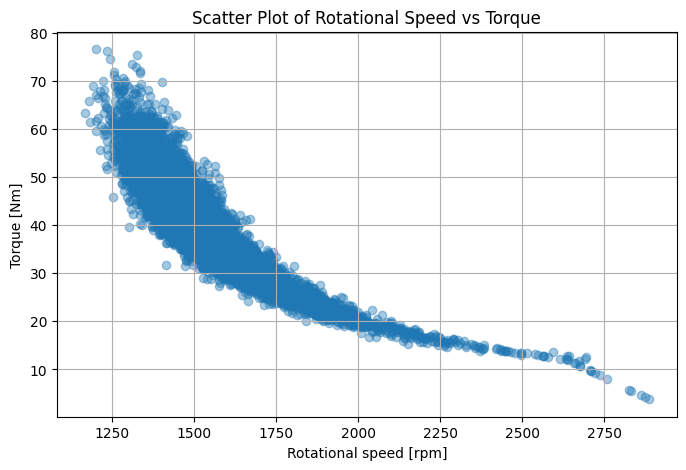

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(df["Rotational speed [rpm]"], df["Torque [Nm]"], alpha=0.4)

plt.xlabel("Rotational speed [rpm]")
plt.ylabel("Torque [Nm]")
plt.title("Scatter Plot of Rotational Speed vs Torque")
plt.grid(True)

plt.show()

### Interpretation of the Scatter Plot

The scatter plot shows a negative relationship between rotational speed and torque. As rotational speed increases, torque generally decreases. The points form a curved pattern, suggesting that the relationship is nonlinear rather than perfectly linear. This relationship helps us understand how two machine operating variables behave in the dataset.

In [13]:
correlation=df["Rotational speed [rpm]"].corr(df["Air temperature [K]"])
print("Correlation coefficient:",correlation)

Correlation coefficient: 0.02267045879554712


In [15]:
covariance=df["Rotational speed [rpm]"].cov(df["Torque [Nm]"])
print("Covariance:",covariance)

Covariance: -1563.9107719281926


### Covariance, Correlation and Causation

The covariance between rotational speed and torque was approximately **−1563.91**. The negative value indicates an overall tendency for the two variables to vary in opposite directions.

The Pearson correlation coefficient was approximately **0.02267**, indicating a very weak positive linear relationship. The difference between the covariance and correlation results suggests that a linear measure may not adequately describe the relationship between these variables. The scatter plot should also be considered when interpreting their relationship.

Correlation does not necessarily mean causation. An association between two variables does not prove that one directly causes changes in the other, since other variables may influence both.

### What Do the Statistics Tell Us About the Data?

The descriptive statistics show that air temperature has a mean of approximately 300.00 K and a standard deviation of 2.00 K, while process temperature has a mean of approximately 310.01 K and a standard deviation of 1.48 K. The relatively small standard deviations indicate that both temperature measurements vary within narrower intervals compared with their average values.

Rotational speed has a mean of approximately 1538.78 rpm and a standard deviation of 179.28 rpm, showing variation in the operating speeds represented in the dataset. Torque has a mean of approximately 39.99 Nm and a standard deviation of 9.97 Nm, indicating variation in the torque measurements.

The means and medians of air temperature, process temperature, and torque are close, while rotational speed has a higher mean than median. These statistics help us understand the distribution and variability of the machine operating measurements before investigating their relationships with machine failure.

### Input → Function/Model → Output

For this project, rotational speed is selected as the input variable, while torque is selected as the output variable.

**Input:** Rotational speed (rpm)

**Function/Model:** \(f(x)\), a mathematical model that represents the relationship between rotational speed and torque.

**Output:** Predicted torque (Nm)

The relationship can be expressed mathematically as:

$$
\widehat{\text{Torque}}=f(\text{Rotational Speed})
$$

This expression represents the idea of using a model to predict torque from rotational speed. The model is conceptual and has not yet been trained on the dataset.